# ResNet-18 (ImageNet-initialised)
Owner: Anders

ResNet-18 fine-tuned on the same frozen split as the small CNN, for comparison.

Preprocessing (`load_and_pad`, `normalize_image`) comes from the shared `src/preprocessing.py`
module, so this notebook, the baseline, and the small CNN all preprocess images identically.

In [1]:
import sys
sys.path.append("..")

import kagglehub
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

from src.preprocessing import load_and_pad, normalize_image

IMG_SIZE = 128
SEED = 42
torch.manual_seed(SEED)

# Prefer a GPU: CUDA on other platforms, MPS (Metal) on Apple Silicon, else fall back to CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Using device:", device)

Using device: mps


## Load the frozen split and build a Dataset/DataLoader
Same `CellDataset` pattern as `03_cnn.ipynb`, but with one addition: since we're using
ImageNet-pretrained weights, inputs must be normalized with the same per-channel mean/std
ImageNet was trained with - otherwise the pretrained filters see pixel statistics they were
never trained on, and the pretrained weights stop being a useful starting point. That's what
`normalize_image(img, method="imagenet")` (from `src/preprocessing.py`) does.

In [2]:
manifest = pd.read_csv("../data/splits/patient_split.csv")
print(manifest["split"].value_counts())

# The manifest only stores filename + category, not an absolute path (those differ per machine).
# Rebuild the path the same way 00_eda.ipynb resolved it: <kagglehub download root>/<category>/<filename>
download_path = Path(kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria"))
data_dir = download_path / "cell_images"
if (data_dir / "cell_images").exists():
    data_dir = data_dir / "cell_images"

CLASS_TO_IDX = {"Uninfected": 0, "Parasitized": 1}


class CellDataset(Dataset):
    def __init__(self, df: pd.DataFrame, data_dir: Path):
        self.df = df.reset_index(drop=True)
        self.data_dir = data_dir

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        path = self.data_dir / row["category"] / row["filename"]

        # load_and_pad returns (height, width, channels) in [0, 1]; normalize_image applies the
        # ImageNet mean/std; then rearrange to (channels, height, width) for PyTorch.
        img = load_and_pad(str(path), IMG_SIZE)
        img = normalize_image(img, method="imagenet")
        img = torch.from_numpy(img.astype(np.float32)).permute(2, 0, 1)

        label = CLASS_TO_IDX[row["category"]]
        return img, label


train_ds = CellDataset(manifest[manifest["split"] == "train"], data_dir)
val_ds = CellDataset(manifest[manifest["split"] == "val"], data_dir)
test_ds = CellDataset(manifest[manifest["split"] == "test"], data_dir)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Sanity check: one batch
images, labels = next(iter(train_loader))
print(images.shape, images.dtype, labels.shape)

split
train    19124
val       4324
test      4110
Name: count, dtype: int64


torch.Size([64, 3, 128, 128]) torch.float32 torch.Size([64])


## ResNet-18 implementation
Load ImageNet-pretrained weights, then replace the final classification layer (`fc`), which was
built for ImageNet's 1000 classes, with one sized for our 2 classes. Everything else keeps its
pretrained weights as the starting point, and all layers are fine-tuned (not frozen).

In [3]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# fc is the final linear layer; in_features is however many features ResNet-18's conv backbone
# produces (512), so we keep that and only change out_features to our 2 classes.
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
# Lower learning rate than the small CNN (1e-3): most of this network is already pretrained,
# so we want smaller updates that don't wreck the pretrained features early in training.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

## Training loop (validation only - freeze the protocol before touching test_loader)

In [4]:
from sklearn.metrics import (
    f1_score, roc_auc_score, roc_curve, confusion_matrix,
    precision_score, recall_score, precision_recall_curve,
)


def run_epoch(loader, train: bool):
    model.train(mode=train)
    total_loss, correct, n = 0.0, 0, 0
    all_labels, all_preds, all_probs = [], [], []

    # Iterates over 1 batch at a time (up to 64 images and 64 labels)
    for images, labels in loader:

        images, labels = images.to(device), labels.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        n += images.size(0)

        # softmax turns the 2 raw logits into class probabilities that sum to 1;
        # we keep index 1 (probability of "Parasitized") for ROC-AUC, which needs
        # probabilities rather than hard 0/1 predictions.
        probs = torch.softmax(outputs, dim=1)[:, 1]
        all_labels.extend(labels.cpu().tolist())
        all_preds.extend(preds.cpu().tolist())
        all_probs.extend(probs.detach().cpu().tolist())

    # Every metric below is computed once over the whole epoch's predictions, not averaged
    # per batch - a single batch's TP/FP/FN counts are too small and skewed on their own.
    # precision/recall/f1 here are measured at the default 0.5 decision threshold (argmax).
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    roc_auc = roc_auc_score(all_labels, all_probs)
    cm = confusion_matrix(all_labels, all_preds)
    # fpr/tpr and pr_precision/pr_recall sweep every possible threshold, for the ROC and
    # precision-recall curves below - distinct from the single-threshold scores above.
    fpr, tpr, _ = roc_curve(all_labels, all_probs)
    pr_precision, pr_recall, _ = precision_recall_curve(all_labels, all_probs)

    return {
        "loss": total_loss / n,
        "acc": correct / n,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "cm": cm,
        "fpr": fpr,
        "tpr": tpr,
        "pr_precision": pr_precision,
        "pr_recall": pr_recall,
    }


# NUM_EPOCHS is an upper bound - early stopping (below) decides the actual run length.
NUM_EPOCHS = 20
# Early stopping: stop once val_loss hasn't improved by at least MIN_DELTA (relative) for
# PATIENCE consecutive epochs, instead of us eyeballing the printed numbers to decide when
# more epochs stop being worth it.
PATIENCE = 2
MIN_DELTA = 0.01  # require >= 1% relative improvement in val_loss to count as progress

history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_precision": [], "val_precision": [],
    "train_recall": [], "val_recall": [],
    "train_f1": [], "val_f1": [],
    "train_auc": [], "val_auc": [],
}

best_val_loss = None
epochs_without_improvement = 0

for epoch in range(1, NUM_EPOCHS + 1):
    train_metrics = run_epoch(train_loader, train=True)
    val_metrics = run_epoch(val_loader, train=False)

    for key in ("loss", "acc", "precision", "recall", "f1"):
        history[f"train_{key}"].append(train_metrics[key])
        history[f"val_{key}"].append(val_metrics[key])
    history["train_auc"].append(train_metrics["roc_auc"])
    history["val_auc"].append(val_metrics["roc_auc"])

    print(f"Epoch {epoch}: "
          f"train_loss={train_metrics['loss']:.4f} train_acc={train_metrics['acc']:.4f} "
          f"train_precision={train_metrics['precision']:.4f} train_recall={train_metrics['recall']:.4f} "
          f"train_f1={train_metrics['f1']:.4f} train_auc={train_metrics['roc_auc']:.4f} | "
          f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['acc']:.4f} "
          f"val_precision={val_metrics['precision']:.4f} val_recall={val_metrics['recall']:.4f} "
          f"val_f1={val_metrics['f1']:.4f} val_auc={val_metrics['roc_auc']:.4f}")
    print("val confusion matrix:\n", val_metrics["cm"])

    # First epoch always "improves" (nothing to compare against yet).
    if best_val_loss is None:
        best_val_loss = val_metrics["loss"]
    else:
        relative_improvement = (best_val_loss - val_metrics["loss"]) / best_val_loss
        if relative_improvement >= MIN_DELTA:
            best_val_loss = val_metrics["loss"]
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print(f"Early stopping at epoch {epoch}: val_loss improved by less than "
                      f"{MIN_DELTA:.0%} for {PATIENCE} consecutive epochs.")
                break

# Keep the final epoch's val metrics around for the ROC/PR curve plots below.
final_val_metrics = val_metrics

Epoch 1: train_loss=0.1316 train_acc=0.9510 train_precision=0.9572 train_recall=0.9440 train_f1=0.9505 train_auc=0.9887 | val_loss=0.1249 val_acc=0.9556 val_precision=0.9684 val_recall=0.9461 val_f1=0.9571 val_auc=0.9903
val confusion matrix:
 [[1990   70]
 [ 122 2142]]


Epoch 2: train_loss=0.0683 train_acc=0.9751 train_precision=0.9817 train_recall=0.9681 train_f1=0.9748 train_auc=0.9967 | val_loss=0.1185 val_acc=0.9618 val_precision=0.9621 val_recall=0.9651 val_f1=0.9636 val_auc=0.9921
val confusion matrix:
 [[1974   86]
 [  79 2185]]


Epoch 3: train_loss=0.0428 train_acc=0.9844 train_precision=0.9886 train_recall=0.9800 train_f1=0.9843 train_auc=0.9987 | val_loss=0.1356 val_acc=0.9519 val_precision=0.9416 val_recall=0.9682 val_f1=0.9547 val_auc=0.9908
val confusion matrix:
 [[1924  136]
 [  72 2192]]


Epoch 4: train_loss=0.0311 train_acc=0.9876 train_precision=0.9900 train_recall=0.9851 train_f1=0.9876 train_auc=0.9993 | val_loss=0.1594 val_acc=0.9577 val_precision=0.9719 val_recall=0.9466 val_f1=0.9591 val_auc=0.9905
val confusion matrix:
 [[1998   62]
 [ 121 2143]]
Early stopping at epoch 4: val_loss improved by less than 1% for 2 consecutive epochs.


## Learning curves
Train vs. validation loss and accuracy across epochs
A widening gap (train still improving, val flat/worsening) signals overfitting.

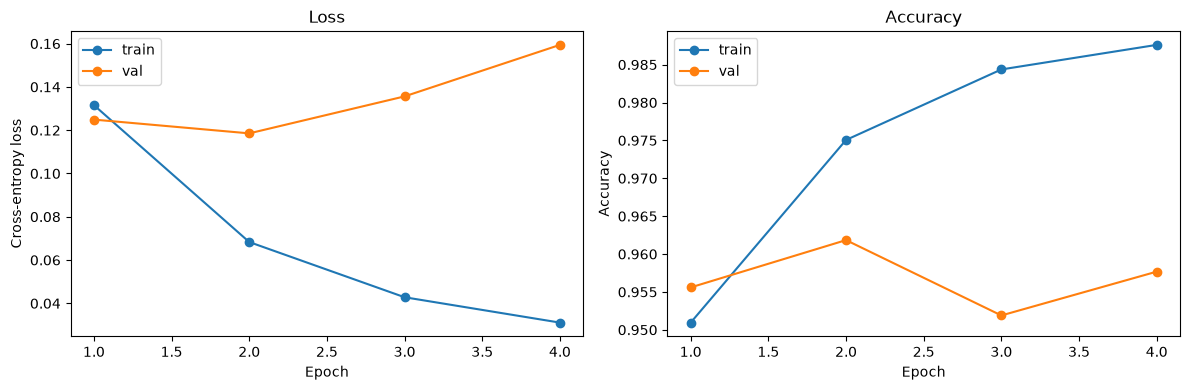

In [5]:
import matplotlib.pyplot as plt

# Use the actual number of epochs that ran, not NUM_EPOCHS - early stopping may have cut it short.
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="train")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="train")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## Confusion matrix (final epoch, validation set)
Same style as Shania's Grad-CAM notebook, so the plots look consistent across the project.
Percentages are row-normalized (share of each true class), matching `CLASS_TO_IDX`'s ordering
(`0 = Uninfected, 1 = Parasitized`) for both axes.

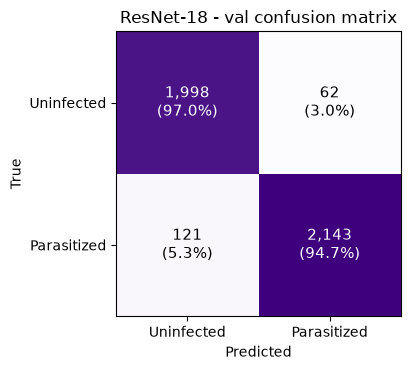

In [6]:
cm = final_val_metrics["cm"]
class_names = ["Uninfected", "Parasitized"]

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(cm, cmap="Purples")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
ax.set_xticks([0, 1], class_names)
ax.set_yticks([0, 1], class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("ResNet-18 - val confusion matrix")
plt.tight_layout()
plt.show()

## ROC curve (final epoch, validation set)
The dashed diagonal is the random-guess baseline (AUC = 0.5): a model with no real discriminative
power would produce a ROC curve that tracks this line on average. The further the actual curve
bows toward the top-left corner (high true-positive rate at a low false-positive rate), the better
the model is than chance.

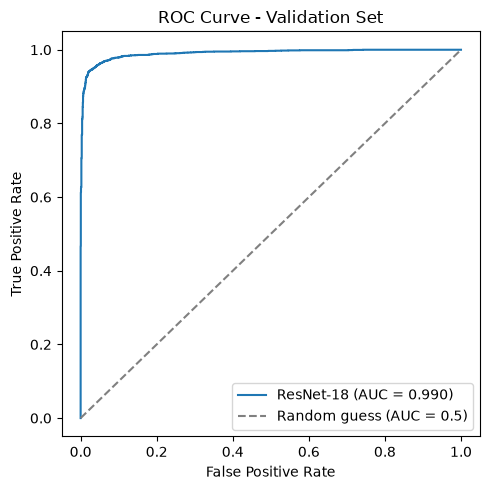

In [7]:
plt.figure(figsize=(5, 5))
plt.plot(final_val_metrics["fpr"], final_val_metrics["tpr"],
         label=f"ResNet-18 (AUC = {final_val_metrics['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set")
plt.legend()
plt.tight_layout()
plt.show()

## Precision-Recall curve (final epoch, validation set)
The dashed horizontal line is the random-guess baseline: a classifier with no real
discriminative power would have precision roughly equal to the positive class's share of
the validation set, regardless of recall. A curve staying above that line, especially as
recall approaches 1, means the model ranks true positives ahead of negatives better than chance.

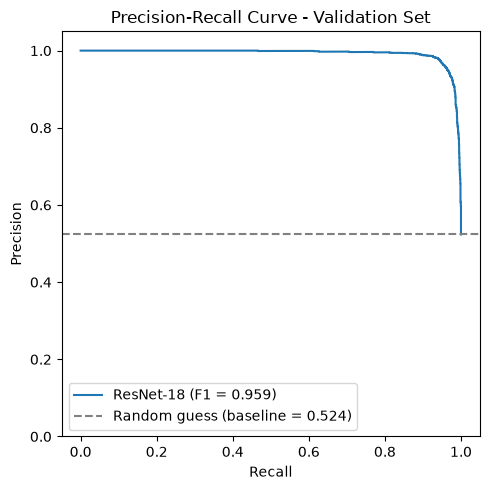

In [8]:
plt.figure(figsize=(5, 5))
plt.plot(final_val_metrics["pr_recall"], final_val_metrics["pr_precision"],
         label=f"ResNet-18 (F1 = {final_val_metrics['f1']:.3f})")

# Baseline: the positive class's prevalence in the validation set (what a random classifier's
# precision would hover around, regardless of threshold/recall).
baseline = (val_ds.df["category"] == "Parasitized").mean()
plt.axhline(baseline, linestyle="--", color="gray", label=f"Random guess (baseline = {baseline:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Validation Set")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

## Save the trained model
Writes the trained weights (plus the bits needed to use them later: image size, ImageNet
normalization stats, class index mapping) to `models/resnet18.pt`, so Shania can load this
model for Grad-CAM without retraining it.

In [9]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "resnet18.pt"

# Load with: checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)
#            model = resnet18(weights=None); model.fc = nn.Linear(model.fc.in_features, 2)
#            model.load_state_dict(checkpoint["model_state_dict"])
#            preprocess with: normalize_image(load_and_pad(path, checkpoint["img_size"]),
#                                              method=checkpoint["normalize_method"])
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": CLASS_TO_IDX,
    "img_size": IMG_SIZE,
    "normalize_method": "imagenet",
    "val_metrics": {k: v for k, v in final_val_metrics.items() if k not in ("fpr", "tpr", "pr_precision", "pr_recall")},
}, MODEL_PATH)

print(f"Saved trained ResNet-18 to {MODEL_PATH}")

Saved trained ResNet-18 to ../models/resnet18.pt
